# 04 SRTM coastal DEM and slope

**Manuscript outputs:** Figure S3; clipped and projected DEM used by stage 05

**Inputs:** SRTM 30 m DEM (not stored in the repository; download it, see Data/README.md)

The earlier Part B of this notebook (pixel slopes at shoreline intersections) was a development step. It was replaced by the profile method in stage 05 and has been removed here.

Inputs are read from `Master_raw/`; everything produced is written to `Outputs/` (manuscript figures in `Outputs/Figures`, tables in `Outputs/Tables`). The first code cell lists every path. Run the cells in order.

# SRTM Elevation, Slope Development, and Transect Slope Extraction

**Project:** Kenyan Coast Shoreline Uncertainty Analysis  
**Author:** James Mbugua  
**Registration:** ENC324-1769/2022

## Purpose

This notebook prepares a slope surface for the shoreline uncertainty analysis. It performs four main tasks:

1. Reads and inspects the East Africa SRTM 30 m elevation raster.
2. Produces a colour elevation visualisation.
3. Clips the raster to a configurable Kenyan coastal processing window, reprojects it to a metric coordinate system, and calculates slope in degrees.
4. Provides a later section for extracting slope values to DSAS transects using latitude and longitude.

The slope in degrees will later be used in the tidal shoreline uncertainty conversion:

\[
U_{tide} = \frac{U_{\eta}}{\tan(\beta)}
\]

where \(\beta\) is the local slope angle in degrees.

### Important methodological note

The SRTM raster is likely in a geographic coordinate system. Slope must not be calculated directly from longitude and latitude cell sizes because horizontal distances would be in degrees rather than metres. This notebook therefore reprojects the coastal subset to **WGS 84 / UTM Zone 37S, EPSG:32737** before calculating slope.

Because the analysis concerns shoreline position, the resulting SRTM slope should be interpreted as a terrain-slope proxy. A 30 m SRTM DEM may not resolve the true beach-face or intertidal slope, so sensitivity and limitations should be reported when this slope is used in the final \(U_{tide}\) calculation.

## 1. Imports and project paths

Edit only the paths in this section if your directory structure changes.

In [3]:
from pathlib import Path

# ------------------------------------------------------------
# REPOSITORY ROOT: first folder above this notebook that contains Master_raw
# (e.g. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024)
# ------------------------------------------------------------
_here = Path.cwd().resolve()
ROOT = next((p for p in (_here, *_here.parents) if (p / "Master_raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(f"No Master_raw folder found above {_here}. Open this notebook inside the repository.")
RAW = ROOT / "Master_raw"          # inputs
OUTPUTS = ROOT / "Outputs"         # everything this repository produces
FIGURES = OUTPUTS / "Figures"      # manuscript figures
TABLES = OUTPUTS / "Tables"        # manuscript tables
TEXT_STATS = TABLES / "Text_statistics"
for _d in (FIGURES, TABLES, TEXT_STATS):
    _d.mkdir(parents=True, exist_ok=True)
OVERWRITE = True                   # re-running replaces this notebook's earlier outputs


def first_existing(*candidates):
    """Return the first path that exists (otherwise the first one)."""
    for c in candidates:
        if Path(c).exists():
            return Path(c)
    return Path(candidates[0])


def save_table(df, name, index=False, folder=None):
    path = (folder or TABLES) / f"{name}.csv"
    df.to_csv(path, index=index, encoding="utf-8-sig")
    print("Saved:", path)


def save_figure(fig, name, dpi=600):
    for ext in ("jpg",):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=dpi, bbox_inches="tight", pil_kwargs=({"quality": 95} if ext == "jpg" else None))
    print("Saved:", FIGURES / f"{name}.jpg")


def remove_existing(*files):
    for f in map(Path, files):
        for t in (list(f.parent.glob(f.stem + ".*")) if f.suffix == ".shp" else [f]):
            if t.exists():
                if not OVERWRITE:
                    raise FileExistsError(t)
                t.unlink()

# ------------------------------------------------------------
# INPUTS AND OUTPUT FOLDERS FOR THIS NOTEBOOK
# ------------------------------------------------------------
SRTM_DEM = first_existing(
    RAW / "Elevation" / "East Africa_SRTM_30m.tif",
    Path(r"F:\ZoldJMB_Backup_March_31_2022\2_CORDIO_GIS_lab\Physical_Geography\Elevation\East Africa_SRTM_30m.tif"),
)
ELEVATION_DIR = OUTPUTS / "Elevation_slope"
DEM_WGS84_TIF = ELEVATION_DIR / "Kenya_Coast_SRTM30m_WGS84.tif"
DEM_UTM_TIF = ELEVATION_DIR / "Kenya_Coast_SRTM30m_UTM37S.tif"
SLOPE_DEG_TIF = ELEVATION_DIR / "Kenya_Coast_SRTM30m_Slope_Degrees.tif"
SLOPE_PCT_TIF = ELEVATION_DIR / "Kenya_Coast_SRTM30m_Slope_Percent.tif"

print("Repository root:", ROOT)
for _label, _p in [("SRTM_DEM", SRTM_DEM)]:
    print(f"  {'ok     ' if _p.exists() else 'MISSING'} {_label}: {_p.relative_to(ROOT) if _p.is_relative_to(ROOT) else _p}")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
from rasterio.windows import from_bounds
from rasterio.transform import array_bounds
from rasterio.warp import (
    calculate_default_transform,
    reproject,
    Resampling,
    transform_bounds,
)
from rasterio.mask import mask

# Optional packages used later for vector transect data
try:
    import geopandas as gpd
except ImportError:
    gpd = None

# ------------------------------------------------------------
# INPUT AND OUTPUT PATHS
# ------------------------------------------------------------

DEM_FILE = SRTM_DEM


OUTPUT_DIR = ELEVATION_DIR

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Main outputs
COASTAL_DEM_WGS84 = DEM_WGS84_TIF
COASTAL_DEM_UTM = DEM_UTM_TIF
SLOPE_DEG_FILE = SLOPE_DEG_TIF
SLOPE_PCT_FILE = SLOPE_PCT_TIF

ELEVATION_FIGURE = OUTPUT_DIR / "Kenya_Coast_SRTM_Elevation_Overview.jpg"
SLOPE_FIGURE = OUTPUT_DIR / "Kenya_Coast_SRTM_Slope_Overview.jpg"

print("DEM input :", DEM_FILE)
print("Output dir:", OUTPUT_DIR)

Repository root: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024
  ok      SRTM_DEM: F:\ZoldJMB_Backup_March_31_2022\2_CORDIO_GIS_lab\Physical_Geography\Elevation\East Africa_SRTM_30m.tif
DEM input : F:\ZoldJMB_Backup_March_31_2022\2_CORDIO_GIS_lab\Physical_Geography\Elevation\East Africa_SRTM_30m.tif
Output dir: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Elevation_slope


## 2. Inspect the source SRTM raster

This step checks that the source raster exists and reports its dimensions, coordinate system, pixel size, bounds, nodata value and elevation range.

The elevation range is calculated from a downsampled read so that a very large East Africa raster does not need to be loaded fully into memory.

In [4]:
if not DEM_FILE.exists():
    raise FileNotFoundError(
        f"DEM not found:\n{DEM_FILE}\n\n"
        "Download the SRTM 30 m DEM and place it at this path (see Data/README.md).\n"
        "If you only need Figure S3 and the clipped DEMs already exist, run the first cell and then the Figure S3 cell."
    )

with rasterio.open(DEM_FILE) as src:
    print("Raster information")
    print("------------------")
    print("Driver       :", src.driver)
    print("CRS          :", src.crs)
    print("Width        :", src.width)
    print("Height       :", src.height)
    print("Band count   :", src.count)
    print("Pixel size   :", src.res)
    print("Bounds       :", src.bounds)
    print("NoData       :", src.nodata)
    print("Data type    :", src.dtypes[0])

    # Downsample for quick statistical inspection
    max_preview = 1500
    scale = max(src.width / max_preview, src.height / max_preview, 1)

    preview_h = max(1, int(src.height / scale))
    preview_w = max(1, int(src.width / scale))

    dem_preview = src.read(
        1,
        out_shape=(preview_h, preview_w),
        resampling=Resampling.average,
        masked=True,
    )

    print("\nApproximate elevation statistics from preview")
    print("---------------------------------------------")
    print("Minimum elevation :", float(dem_preview.min()), "m")
    print("Maximum elevation :", float(dem_preview.max()), "m")
    print("Mean elevation    :", float(dem_preview.mean()), "m")

Raster information
------------------
Driver       : GTiff
CRS          : EPSG:4326
Width        : 46912
Height       : 58982
Band count   : 1
Pixel size   : (0.00027777777777777794, 0.000277777777777778)
Bounds       : BoundingBox(left=28.856527777777774, bottom=-11.749861111111137, right=41.887638888888894, top=4.634027777777764)
NoData       : -3.4028230607370965e+38
Data type    : float32

Approximate elevation statistics from preview
---------------------------------------------
Minimum elevation : -2.157109498977661 m
Maximum elevation : 5758.08447265625 m
Mean elevation    : 977.624913734717 m


## 3. Visualise the East Africa elevation raster

A downsampled copy is used for display only. The original raster values are not altered.

The `terrain` colour map is used because it visually separates lower coastal elevations from higher inland terrain.

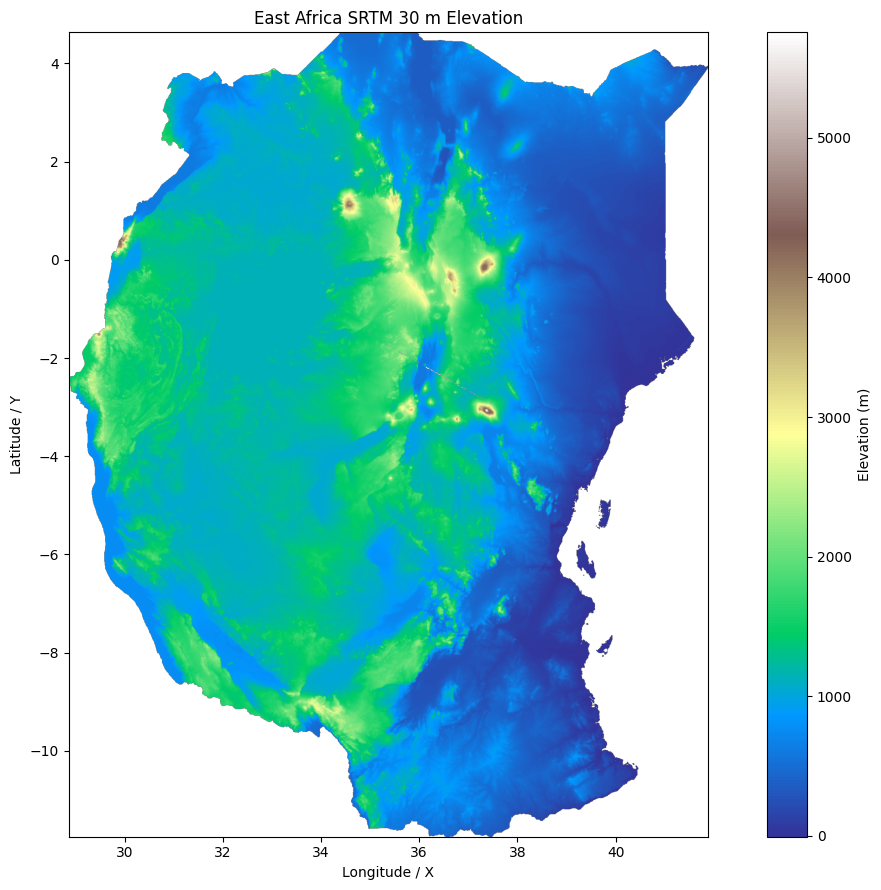

In [5]:
with rasterio.open(DEM_FILE) as src:
    max_preview = 1800
    scale = max(src.width / max_preview, src.height / max_preview, 1)

    preview_h = max(1, int(src.height / scale))
    preview_w = max(1, int(src.width / scale))

    arr = src.read(
        1,
        out_shape=(preview_h, preview_w),
        resampling=Resampling.average,
        masked=True,
    )

    left, bottom, right, top = src.bounds

plt.figure(figsize=(12, 9))
im = plt.imshow(
    arr,
    cmap="terrain",
    extent=[left, right, bottom, top],
    origin="upper"
)
plt.colorbar(im, label="Elevation (m)")
plt.xlabel("Longitude / X")
plt.ylabel("Latitude / Y")
plt.title("East Africa SRTM 30 m Elevation")
plt.tight_layout()
plt.show()

## 4. Define the Kenyan coastal processing window

Processing the complete East Africa SRTM raster is unnecessary for the shoreline study and could be computationally expensive.

The default bounding box below is a broad coastal working window around the Kenyan coast. It can be refined later using the actual transect extent.

The coordinates are in WGS 84 longitude and latitude:

- west: 38.5° E
- south: 5.0° S
- east: 42.0° E
- north: 1.5° S

This is intentionally broader than the immediate shoreline so that the coastal terrain remains available around the transects.

In [6]:
# Broad Kenyan coastal processing window in WGS84
COAST_BBOX_WGS84 = {
    "west": 38.5,
    "south": -5.0,
    "east": 42.0,
    "north": -1.5,
}

COAST_BBOX_WGS84

{'west': 38.5, 'south': -5.0, 'east': 42.0, 'north': -1.5}

## 5. Clip the SRTM raster to the Kenyan coastal window

The clipping step preserves the source raster coordinate system and resolution. The result is written as a GeoTIFF for inspection and reproducibility.

In [7]:
with rasterio.open(DEM_FILE) as src:
    if src.crs is None:
        raise ValueError("The source DEM has no CRS. Stop and inspect the raster metadata.")

    # Convert the WGS84 processing bounds into the DEM CRS if necessary
    if src.crs.to_epsg() == 4326:
        clip_bounds = (
            COAST_BBOX_WGS84["west"],
            COAST_BBOX_WGS84["south"],
            COAST_BBOX_WGS84["east"],
            COAST_BBOX_WGS84["north"],
        )
    else:
        clip_bounds = transform_bounds(
            "EPSG:4326",
            src.crs,
            COAST_BBOX_WGS84["west"],
            COAST_BBOX_WGS84["south"],
            COAST_BBOX_WGS84["east"],
            COAST_BBOX_WGS84["north"],
            densify_pts=21,
        )

    # Intersect requested bounds with source raster bounds
    west = max(clip_bounds[0], src.bounds.left)
    south = max(clip_bounds[1], src.bounds.bottom)
    east = min(clip_bounds[2], src.bounds.right)
    north = min(clip_bounds[3], src.bounds.top)

    if west >= east or south >= north:
        raise ValueError(
            "The requested coastal bounding box does not overlap the DEM."
        )

    window = from_bounds(west, south, east, north, src.transform)
    window = window.round_offsets().round_lengths()

    coastal = src.read(1, window=window, masked=True)
    coastal_transform = src.window_transform(window)

    profile = src.profile.copy()
    profile.update(
        height=coastal.shape[0],
        width=coastal.shape[1],
        transform=coastal_transform,
        compress="deflate",
        tiled=True,
    )

    fill_value = src.nodata if src.nodata is not None else -9999
    profile.update(nodata=fill_value)

    with rasterio.open(COASTAL_DEM_WGS84, "w", **profile) as dst:
        dst.write(coastal.filled(fill_value), 1)

print("Saved coastal DEM:")
print(COASTAL_DEM_WGS84)
print("Shape:", coastal.shape)

Saved coastal DEM:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Elevation_slope\Kenya_Coast_SRTM30m_WGS84.tif
Shape: (12600, 12196)


## 6. Visualise the clipped Kenyan coastal elevation raster

This view should be inspected before continuing. Confirm that the raster covers the Kenyan coastal belt needed for the DSAS transects and that the elevation values look reasonable.

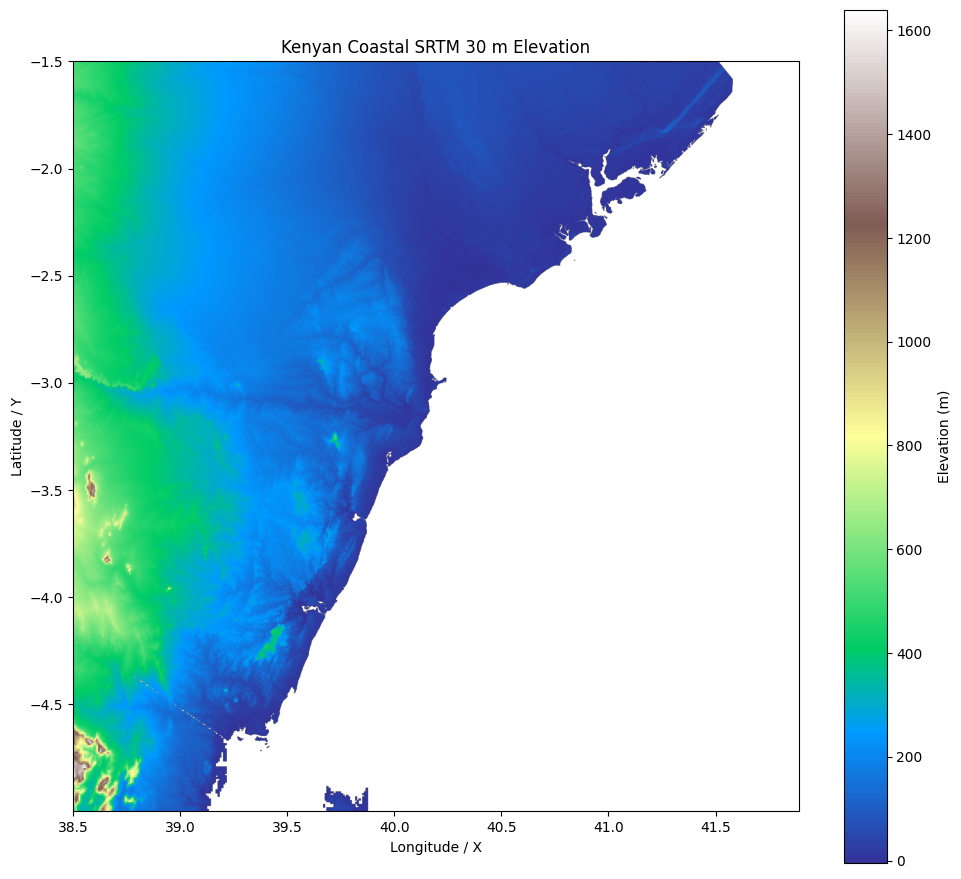

Saved elevation figure:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Elevation_slope\Kenya_Coast_SRTM_Elevation_Overview.png


In [8]:
with rasterio.open(COASTAL_DEM_WGS84) as src:
    max_preview = 1800
    scale = max(src.width / max_preview, src.height / max_preview, 1)

    preview_h = max(1, int(src.height / scale))
    preview_w = max(1, int(src.width / scale))

    coastal_preview = src.read(
        1,
        out_shape=(preview_h, preview_w),
        resampling=Resampling.average,
        masked=True,
    )

    left, bottom, right, top = src.bounds

plt.figure(figsize=(10, 9))
im = plt.imshow(
    coastal_preview,
    cmap="terrain",
    extent=[left, right, bottom, top],
    origin="upper"
)
plt.colorbar(im, label="Elevation (m)")
plt.xlabel("Longitude / X")
plt.ylabel("Latitude / Y")
plt.title("Kenyan Coastal SRTM 30 m Elevation")
plt.tight_layout()
plt.savefig(ELEVATION_FIGURE, dpi=200, bbox_inches="tight", pil_kwargs={"quality": 95})
plt.show()

print("Saved elevation figure:")
print(ELEVATION_FIGURE)

## 7. Reproject the coastal DEM to UTM Zone 37S

Slope requires horizontal and vertical units to be compatible. The coastal DEM is therefore reprojected to **EPSG:32737**, where horizontal coordinates are measured in metres.

A target resolution of 30 m is retained to match the nominal SRTM resolution.

In [9]:
TARGET_CRS = "EPSG:32737"
TARGET_RESOLUTION = 30.0

with rasterio.open(COASTAL_DEM_WGS84) as src:
    transform, width, height = calculate_default_transform(
        src.crs,
        TARGET_CRS,
        src.width,
        src.height,
        *src.bounds,
        resolution=TARGET_RESOLUTION,
    )

    profile = src.profile.copy()
    profile.update(
        crs=TARGET_CRS,
        transform=transform,
        width=width,
        height=height,
        compress="deflate",
        tiled=True,
    )

    with rasterio.open(COASTAL_DEM_UTM, "w", **profile) as dst:
        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs=TARGET_CRS,
            resampling=Resampling.bilinear,
            src_nodata=src.nodata,
            dst_nodata=src.nodata,
        )

print("Saved projected coastal DEM:")
print(COASTAL_DEM_UTM)

Saved projected coastal DEM:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Elevation_slope\Kenya_Coast_SRTM30m_UTM37S.tif


## 8. Calculate slope in degrees and percent

Slope is calculated from the projected elevation surface using the horizontal elevation gradients in the X and Y directions.

For elevation \(z\),

\[
S = \sqrt{
\left(

rac{\partial z}{\partial x}
ight)^2 +
\left(

rac{\partial z}{\partial y}
ight)^2
}
\]

Slope in degrees is:

\[
eta = rctan(S)	imes

rac{180}{\pi}
\]

and slope percent is:

\[
100S
\]

The slope in degrees is the value needed later for the \(U_{tide}\) calculation.

In [10]:
with rasterio.open(COASTAL_DEM_UTM) as src:
    dem = src.read(1, masked=True).astype("float64")
    profile = src.profile.copy()
    transform = src.transform
    nodata = src.nodata

    xres = abs(transform.a)
    yres = abs(transform.e)

    # Fill nodata temporarily with NaN so gradients do not use nodata values
    z = dem.filled(np.nan)

    dz_dy, dz_dx = np.gradient(
        z,
        yres,
        xres
    )

    rise_run = np.sqrt(
        dz_dx**2 + dz_dy**2
    )

    slope_deg = np.degrees(
        np.arctan(rise_run)
    )

    slope_pct = rise_run * 100.0

    # Reinstate nodata mask and any edge/NaN effects
    invalid = (
        np.ma.getmaskarray(dem)
        | ~np.isfinite(slope_deg)
        | ~np.isfinite(slope_pct)
    )

    slope_deg = np.ma.array(
        slope_deg,
        mask=invalid
    )

    slope_pct = np.ma.array(
        slope_pct,
        mask=invalid
    )

    out_nodata = -9999.0

    slope_profile = profile.copy()
    slope_profile.update(
        dtype="float32",
        nodata=out_nodata,
        compress="deflate",
        tiled=True,
    )

    with rasterio.open(SLOPE_DEG_FILE, "w", **slope_profile) as dst:
        dst.write(
            slope_deg.filled(out_nodata).astype("float32"),
            1
        )

    with rasterio.open(SLOPE_PCT_FILE, "w", **slope_profile) as dst:
        dst.write(
            slope_pct.filled(out_nodata).astype("float32"),
            1
        )

print("Saved slope in degrees:")
print(SLOPE_DEG_FILE)

print("\nSaved slope in percent:")
print(SLOPE_PCT_FILE)

Saved slope in degrees:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Elevation_slope\Kenya_Coast_SRTM30m_Slope_Degrees.tif

Saved slope in percent:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Elevation_slope\Kenya_Coast_SRTM30m_Slope_Percent.tif


## 9. Inspect slope statistics

Very steep values or a large number of zeros should be checked carefully. Coastal SRTM slope can be affected by vegetation, built structures, interpolation and the inability of a 30 m DEM to represent narrow beach profiles.

In [11]:
with rasterio.open(SLOPE_DEG_FILE) as src:
    slope = src.read(1, masked=True)

    values = slope.compressed()
    values = values[np.isfinite(values)]

summary = pd.Series(values).describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

display(summary.to_frame("slope_degrees"))

print("\nAdditional checks")
print("-----------------")
print("Valid cells             :", len(values))
print("Cells <= 0 degrees      :", int(np.sum(values <= 0)))
print("Cells < 0.1 degrees     :", int(np.sum(values < 0.1)))
print("Cells > 30 degrees      :", int(np.sum(values > 30)))

,slope_degrees
count,8.146905e+07
mean,2.266346e+00
std,3.070551e+00
min,0.000000e+00
1%,0.000000e+00
5%,0.000000e+00
25%,9.983512e-01
50%,1.756286e+00
75%,2.749758e+00
95%,5.509604e+00



Additional checks
-----------------
Valid cells             : 81469046
Cells <= 0 degrees      : 4716608
Cells < 0.1 degrees     : 5134371
Cells > 30 degrees      : 156736


## 10. Visualise the coastal slope surface

For visualisation only, the display is capped at the 99th percentile so that a small number of very steep terrain cells do not dominate the colour scale. The underlying slope raster is not clipped or altered.

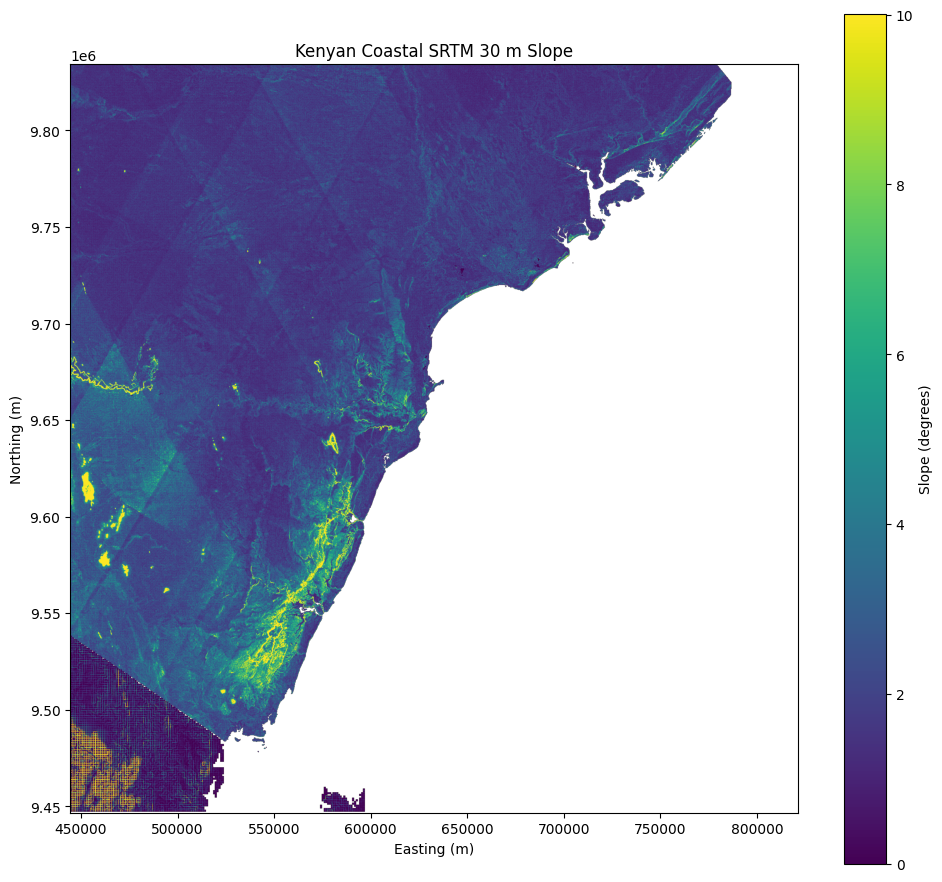

Slope display capped at 99th percentile: 10.014 degrees
Saved slope figure:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Elevation_slope\Kenya_Coast_SRTM_Slope_Overview.png


In [12]:
with rasterio.open(SLOPE_DEG_FILE) as src:
    max_preview = 1800
    scale = max(src.width / max_preview, src.height / max_preview, 1)

    preview_h = max(1, int(src.height / scale))
    preview_w = max(1, int(src.width / scale))

    slope_preview = src.read(
        1,
        out_shape=(preview_h, preview_w),
        resampling=Resampling.average,
        masked=True,
    )

    left, bottom, right, top = src.bounds

display_max = float(
    np.nanpercentile(
        slope_preview.filled(np.nan),
        99
    )
)

plt.figure(figsize=(10, 9))
im = plt.imshow(
    slope_preview,
    cmap="viridis",
    extent=[left, right, bottom, top],
    origin="upper",
    vmin=0,
    vmax=display_max,
)
plt.colorbar(im, label="Slope (degrees)")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.title("Kenyan Coastal SRTM 30 m Slope")
plt.tight_layout()
plt.savefig(SLOPE_FIGURE, dpi=200, bbox_inches="tight", pil_kwargs={"quality": 95})
plt.show()

print("Slope display capped at 99th percentile:", round(display_max, 3), "degrees")
print("Saved slope figure:")
print(SLOPE_FIGURE)

## Figure S3

Uses only the clipped outputs above, so it also runs when the raw SRTM file is not present.

Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Figures\Figure_S3_SRTM_elevation_and_slope.png


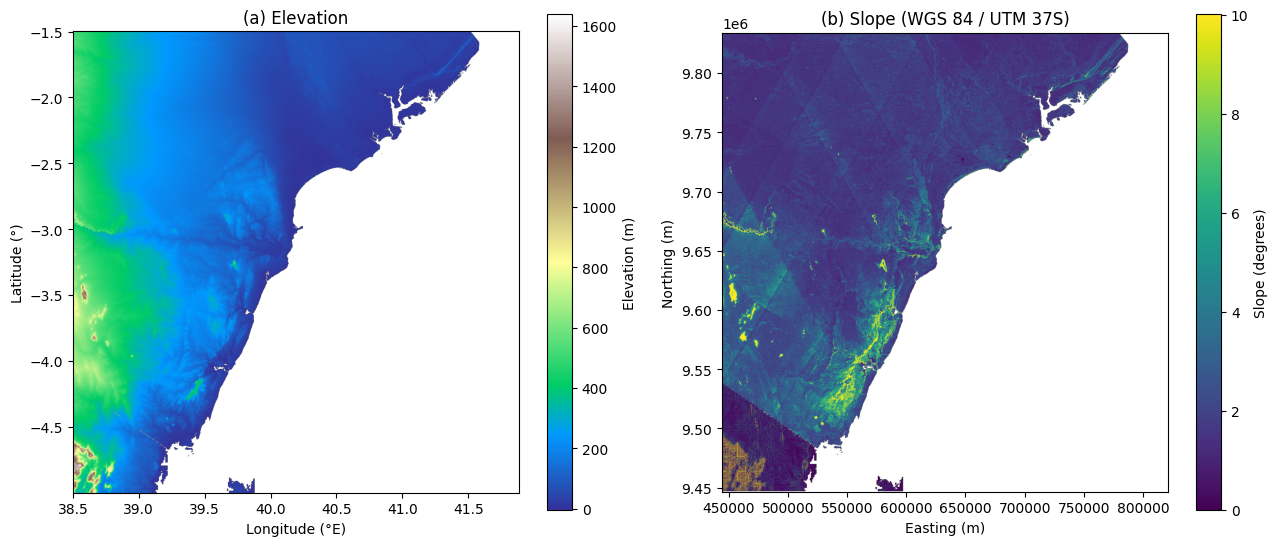

In [13]:
import rasterio
from rasterio.enums import Resampling
import numpy as np
import matplotlib.pyplot as plt

def preview(path, max_px=1800):
    with rasterio.open(path) as src:
        scale = max(src.width / max_px, src.height / max_px, 1)
        arr = src.read(1, out_shape=(max(1, int(src.height / scale)), max(1, int(src.width / scale))),
                       resampling=Resampling.average, masked=True)
        l, b, r, t = src.bounds
    return arr, [l, r, b, t]

elev, ext_e = preview(DEM_WGS84_TIF)
slope, ext_s = preview(SLOPE_DEG_TIF)
vmax = float(np.nanpercentile(slope.filled(np.nan), 99))

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
im0 = axes[0].imshow(elev, cmap="terrain", extent=ext_e, origin="upper")
fig.colorbar(im0, ax=axes[0], label="Elevation (m)", shrink=0.8)
axes[0].set(xlabel="Longitude (\u00b0E)", ylabel="Latitude (\u00b0)", title="(a) Elevation")
im1 = axes[1].imshow(slope, cmap="viridis", extent=ext_s, origin="upper", vmin=0, vmax=vmax)
fig.colorbar(im1, ax=axes[1], label="Slope (degrees)", shrink=0.8)
axes[1].set(xlabel="Easting (m)", ylabel="Northing (m)", title="(b) Slope (WGS 84 / UTM 37S)")
fig.tight_layout()
save_figure(fig, "Figure_S3_SRTM_elevation_and_slope", dpi=300)
plt.show()